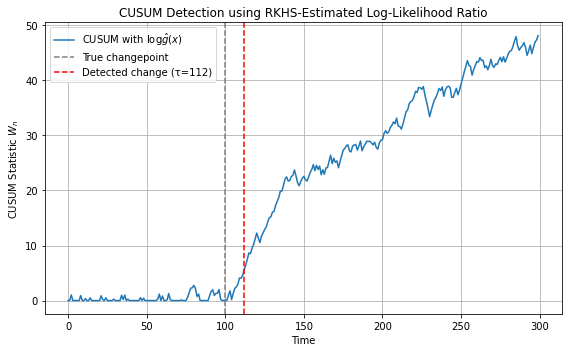

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import sys
import os

# Add local folder to path for imports
sys.path.append('../scripts')
from OracleCUSUM import CUSUM
from EstimatorRKHS import RKHSLikelihoodRatioEstimator

# Generate training data
n_p, n_q = 300, 300
X_p = np.random.normal(loc=1.0, scale=1.0, size=n_p)  # P = N(1,1)
X_q = np.random.normal(loc=0.0, scale=1.0, size=n_q)  # Q = N(0,1)

# Fit RKHS-based LLR estimator
estimator = RKHSLikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
estimator.fit(X_p, X_q)

# Simulate a test stream with change at t=50
n_total = 300
changepoint = 100
stream = np.concatenate([
    np.random.normal(0.0, 1.0, size=changepoint),     # Pre-change (Q)
    np.random.normal(1.0, 1.0, size=n_total - changepoint)  # Post-change (P)
])

# Run CUSUM using estimated log g(x)
log_llrs = estimator.predict_log(stream)
W = np.zeros(n_total)
tau = None
for i in range(1, n_total):
    W[i] = max(0, W[i-1] + log_llrs[i])
    if tau is None and W[i] >= 5.0:
        tau = i

# Plot CUSUM trajectory
plt.figure(figsize=(8, 5))
plt.plot(W, label='CUSUM with $\log \hat{g}(x)$')
plt.axvline(changepoint, color='gray', linestyle='--', label='True changepoint')
if tau is not None:
    plt.axvline(tau, color='red', linestyle='--', label=f'Detected change (τ={tau})')
plt.xlabel("Time")
plt.ylabel("CUSUM Statistic $W_n$")
plt.title("CUSUM Detection using RKHS-Estimated Log-Likelihood Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

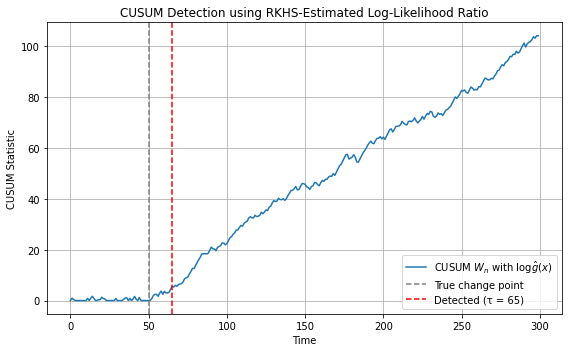

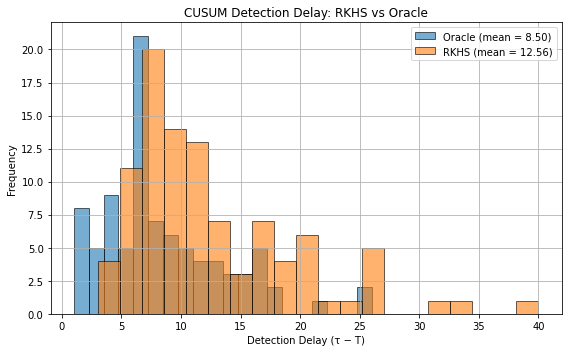

In [4]:
# === RKHS Estimator Class ===
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        n_p = K_PP.shape[0]
        n_q = K_QP.shape[0]
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        term_q = np.mean(g_q)
        term_p = -np.mean(np.log(g_p))
        reg = 0.5 * self.lambda_reg * (alpha @ K_PP @ alpha)
        return term_q + term_p + reg

    def _grad(self, alpha, K_PP, K_QP):
        n_p = K_PP.shape[0]
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        grad_q = np.mean(K_QP, axis=0)
        grad_p = -(K_PP @ (1.0 / g_p)) / n_p
        grad_reg = self.lambda_reg * (K_PP @ alpha)
        return grad_q + grad_p + grad_reg

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        n_p = X_p.shape[0]
        alpha0 = np.ones(n_p) / n_p
        bounds = [(0, None)] * n_p
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=bounds,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            raise RuntimeError("Optimization failed: " + result.message)
        self.alpha = result.x

    def predict(self, X):
        if self.alpha is None or self.X_p is None:
            raise ValueError("Estimator has not been fitted.")
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_xp = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return K_xp @ self.alpha

    def predict_log(self, X):
        g = self.predict(X)
        return np.log(np.clip(g, 1e-8, None))

# === CUSUM Class ===
class CUSUM:
    def __init__(self, threshold):
        self.b = threshold

    def run_with_llrs(self, llrs):
        W = np.zeros_like(llrs)
        tau = None
        for n in range(1, len(llrs)):
            W[n] = max(0, W[n-1] + llrs[n])
            if tau is None and W[n] >= self.b:
                tau = n
        return W, tau

# === Generate training data and fit RKHS estimator ===
n_p, n_q = 300, 300
X_p = np.random.normal(1.0, 1.0, n_p)
X_q = np.random.normal(0.0, 1.0, n_q)

rkhs_est = RKHSLikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
rkhs_est.fit(X_p, X_q)

# === Simulate test stream and run CUSUM ===
changepoint = 50
n_total = 300
stream = np.concatenate([
    np.random.normal(0.0, 1.0, changepoint),   # pre-change (Q)
    np.random.normal(1.0, 1.0, n_total - changepoint)  # post-change (P)
])

log_llrs = rkhs_est.predict_log(stream)
cusum = CUSUM(threshold=5.0)
W, tau = cusum.run_with_llrs(log_llrs)

# === Plot results ===
plt.figure(figsize=(8, 5))
plt.plot(W, label='CUSUM $W_n$ with $\log \hat{g}(x)$')
plt.axvline(changepoint, color='gray', linestyle='--', label='True change point')
if tau is not None:
    plt.axvline(tau, color='red', linestyle='--', label=f'Detected (τ = {tau})')
plt.xlabel("Time")
plt.ylabel("CUSUM Statistic")
plt.title("CUSUM Detection using RKHS-Estimated Log-Likelihood Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Define oracle log-likelihood ratio
def oracle_log_llr(x):
    return np.log(norm.pdf(x, loc=1.0, scale=1.0) / norm.pdf(x, loc=0.0, scale=1.0))

# Run multiple trials and compare RKHS vs Oracle
def compare_rkhs_vs_oracle_cusum(
    n_trials=100, n_total=300, changepoint=50, threshold=5.0,
    n_p=300, n_q=300, sigma=1.0, lambda_reg=1e-2
):
    delays_rkhs = []
    delays_oracle = []

    for seed in range(n_trials):
        np.random.seed(seed)

        # 1. Generate new training data and fit RKHS estimator
        X_p = np.random.normal(1.0, 1.0, n_p)
        X_q = np.random.normal(0.0, 1.0, n_q)
        rkhs_est = RKHSLikelihoodRatioEstimator(sigma=sigma, lambda_reg=lambda_reg)
        rkhs_est.fit(X_p, X_q)

        # 2. Generate test stream
        stream = np.concatenate([
            np.random.normal(0.0, 1.0, changepoint),
            np.random.normal(1.0, 1.0, n_total - changepoint)
        ])

        # 3. Run RKHS-based CUSUM
        log_llrs_rkhs = rkhs_est.predict_log(stream)
        W_rkhs, tau_rkhs = CUSUM(threshold).run_with_llrs(log_llrs_rkhs)
        if tau_rkhs is not None and tau_rkhs > changepoint:
            delays_rkhs.append(tau_rkhs - changepoint)

        # 4. Run Oracle CUSUM
        log_llrs_oracle = oracle_log_llr(stream)
        W_oracle, tau_oracle = CUSUM(threshold).run_with_llrs(log_llrs_oracle)
        if tau_oracle is not None and tau_oracle > changepoint:
            delays_oracle.append(tau_oracle - changepoint)

    return delays_rkhs, delays_oracle

# Run comparison
rkhs_delays, oracle_delays = compare_rkhs_vs_oracle_cusum()

# Plot and compare
plt.figure(figsize=(8, 5))
plt.hist(oracle_delays, bins=20, alpha=0.6, label=f'Oracle (mean = {np.mean(oracle_delays):.2f})', edgecolor='black')
plt.hist(rkhs_delays, bins=20, alpha=0.6, label=f'RKHS (mean = {np.mean(rkhs_delays):.2f})', edgecolor='black')
plt.xlabel("Detection Delay (τ − T)")
plt.ylabel("Frequency")
plt.title("CUSUM Detection Delay: RKHS vs Oracle")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/Oracle_vs_RKHS_Delay.png", dpi=300, bbox_inches='tight')
plt.show()


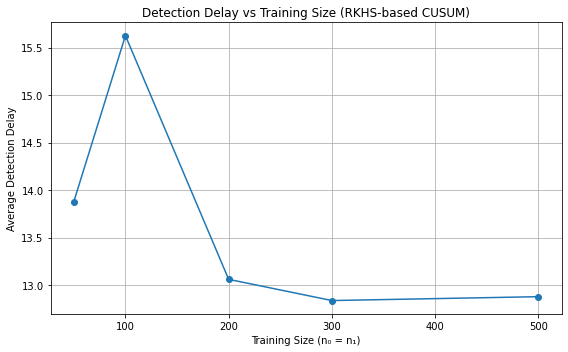

In [5]:
def delay_vs_training_size(
    sizes=np.array([50, 100, 200, 300, 500]), 
    n_trials=50, n_total=300, changepoint=50, threshold=5.0,
    sigma=1.0, lambda_reg=1e-2
):
    avg_delays = []

    for n_train in sizes:
        delays = []
        for seed in range(n_trials):
            np.random.seed(seed)

            # 1. Generate training data
            X_p = np.random.normal(1.0, 1.0, n_train)
            X_q = np.random.normal(0.0, 1.0, n_train)

            # 2. Fit RKHS estimator
            rkhs_est = RKHSLikelihoodRatioEstimator(sigma=sigma, lambda_reg=lambda_reg)
            rkhs_est.fit(X_p, X_q)

            # 3. Generate test stream
            stream = np.concatenate([
                np.random.normal(0.0, 1.0, changepoint),
                np.random.normal(1.0, 1.0, n_total - changepoint)
            ])

            # 4. Run RKHS-based CUSUM
            log_llrs = rkhs_est.predict_log(stream)
            W, tau = CUSUM(threshold).run_with_llrs(log_llrs)
            if tau is not None and tau > changepoint:
                delays.append(tau - changepoint)

        avg_delay = np.mean(delays) if delays else np.nan
        avg_delays.append(avg_delay)

    return sizes, avg_delays

# Run and plot
train_sizes, delays_vs_n = delay_vs_training_size()

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, delays_vs_n, marker='o')
plt.xlabel("Training Size (n₀ = n₁)")
plt.ylabel("Average Detection Delay")
plt.title("Detection Delay vs Training Size (RKHS-based CUSUM)")
plt.grid(True)
plt.tight_layout()
plt.show()